In [2]:
import pandas as pd
import numpy as np
from scipy.stats import norm

In [3]:
df = pd.read_csv("Global_Superstore2.csv", encoding='latin1')
df

#The dataset contained non-UTF-8 characters so specifying encoding ensured correct parsing without data loss

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,32298,CA-2012-124891,31-07-2012,31-07-2012,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,2309.650,7,0.0,762.1845,933.57,Critical
1,26341,IN-2013-77878,05-02-2013,07-02-2013,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",3709.395,9,0.1,-288.7650,923.63,Critical
2,25330,IN-2013-71249,17-10-2013,18-10-2013,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID",5175.171,9,0.1,919.9710,915.49,Medium
3,13524,ES-2013-1579342,28-01-2013,30-01-2013,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless",2892.510,5,0.1,-96.5400,910.16,Medium
4,47221,SG-2013-4320,05-11-2013,06-11-2013,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed",2832.960,8,0.0,311.5200,903.04,Critical
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51285,29002,IN-2014-62366,19-06-2014,19-06-2014,Same Day,KE-16420,Katrina Edelman,Corporate,Kure,Hiroshima,...,OFF-FA-10000746,Office Supplies,Fasteners,"Advantus Thumb Tacks, 12 Pack",65.100,5,0.0,4.5000,0.01,Medium
51286,35398,US-2014-102288,20-06-2014,24-06-2014,Standard Class,ZC-21910,Zuschuss Carroll,Consumer,Houston,Texas,...,OFF-AP-10002906,Office Supplies,Appliances,Hoover Replacement Belt for Commercial Guardsm...,0.444,1,0.8,-1.1100,0.01,Medium
51287,40470,US-2013-155768,02-12-2013,02-12-2013,Same Day,LB-16795,Laurel Beltran,Home Office,Oxnard,California,...,OFF-EN-10001219,Office Supplies,Envelopes,"#10- 4 1/8"" x 9 1/2"" Security-Tint Envelopes",22.920,3,0.0,11.2308,0.01,High
51288,9596,MX-2012-140767,18-02-2012,22-02-2012,Standard Class,RB-19795,Ross Baird,Home Office,Valinhos,São Paulo,...,OFF-BI-10000806,Office Supplies,Binders,"Acco Index Tab, Economy",13.440,2,0.0,2.4000,0.00,Medium


In [4]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,32298,CA-2012-124891,31-07-2012,31-07-2012,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,2309.650,7,0.0,762.1845,933.57,Critical
1,26341,IN-2013-77878,05-02-2013,07-02-2013,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",3709.395,9,0.1,-288.7650,923.63,Critical
2,25330,IN-2013-71249,17-10-2013,18-10-2013,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID",5175.171,9,0.1,919.9710,915.49,Medium
3,13524,ES-2013-1579342,28-01-2013,30-01-2013,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless",2892.510,5,0.1,-96.5400,910.16,Medium
4,47221,SG-2013-4320,05-11-2013,06-11-2013,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed",2832.960,8,0.0,311.5200,903.04,Critical


In [5]:
df.tail()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
51285,29002,IN-2014-62366,19-06-2014,19-06-2014,Same Day,KE-16420,Katrina Edelman,Corporate,Kure,Hiroshima,...,OFF-FA-10000746,Office Supplies,Fasteners,"Advantus Thumb Tacks, 12 Pack",65.100,5,0.0,4.5000,0.01,Medium
51286,35398,US-2014-102288,20-06-2014,24-06-2014,Standard Class,ZC-21910,Zuschuss Carroll,Consumer,Houston,Texas,...,OFF-AP-10002906,Office Supplies,Appliances,Hoover Replacement Belt for Commercial Guardsm...,0.444,1,0.8,-1.1100,0.01,Medium
51287,40470,US-2013-155768,02-12-2013,02-12-2013,Same Day,LB-16795,Laurel Beltran,Home Office,Oxnard,California,...,OFF-EN-10001219,Office Supplies,Envelopes,"#10- 4 1/8"" x 9 1/2"" Security-Tint Envelopes",22.920,3,0.0,11.2308,0.01,High
51288,9596,MX-2012-140767,18-02-2012,22-02-2012,Standard Class,RB-19795,Ross Baird,Home Office,Valinhos,São Paulo,...,OFF-BI-10000806,Office Supplies,Binders,"Acco Index Tab, Economy",13.440,2,0.0,2.4000,0.00,Medium
51289,6147,MX-2012-134460,22-05-2012,26-05-2012,Second Class,MC-18100,Mick Crebagga,Consumer,Tipitapa,Managua,...,OFF-PA-10004155,Office Supplies,Paper,"Eaton Computer Printout Paper, 8.5 x 11",61.380,3,0.0,1.8000,0.00,High


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          51290 non-null  int64  
 1   Order ID        51290 non-null  object 
 2   Order Date      51290 non-null  object 
 3   Ship Date       51290 non-null  object 
 4   Ship Mode       51290 non-null  object 
 5   Customer ID     51290 non-null  object 
 6   Customer Name   51290 non-null  object 
 7   Segment         51290 non-null  object 
 8   City            51290 non-null  object 
 9   State           51290 non-null  object 
 10  Country         51290 non-null  object 
 11  Postal Code     9994 non-null   float64
 12  Market          51290 non-null  object 
 13  Region          51290 non-null  object 
 14  Product ID      51290 non-null  object 
 15  Category        51290 non-null  object 
 16  Sub-Category    51290 non-null  object 
 17  Product Name    51290 non-null 

In [7]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit,Shipping Cost
count,51290.00000,9994.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000
mean,25645.50000,55190.379428,246.490581,3.476545,0.142908,28.610982,26.375915
std,14806.29199,32063.693350,487.565361,2.278766,0.212280,174.340972,57.296804
min,1.00000,1040.000000,0.444000,1.000000,0.000000,-6599.978000,0.000000
25%,12823.25000,23223.000000,30.758625,2.000000,0.000000,0.000000,2.610000
50%,25645.50000,56430.500000,85.053000,3.000000,0.000000,9.240000,7.790000
75%,38467.75000,90008.000000,251.053200,5.000000,0.200000,36.810000,24.450000
max,51290.00000,99301.000000,22638.480000,14.000000,0.850000,8399.976000,933.570000


In [8]:
df.isnull()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51285,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
51286,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
51287,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
51288,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [9]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
51285    False
51286    False
51287    False
51288    False
51289    False
Length: 51290, dtype: bool

In [10]:
df.duplicated().sum()

np.int64(0)

In [32]:
df.sample(10)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority,profit_flag
14427,43284,UP-2012-8290,08-11-2012,12-11-2012,Standard Class,CT-1995,Carol Triggs,Consumer,Donets'k,Donetsk,...,Technology,Copiers,"Hewlett Copy Machine, High-Speed",263.6700,1,0.00,65.9100,20.82,Medium,1
7855,47241,MO-2011-720,03-03-2011,07-03-2011,Standard Class,BW-1200,Ben Wallace,Consumer,Casablanca,Grand Casablanca,...,Technology,Machines,"StarTech Inkjet, White",597.8400,2,0.00,263.0400,43.14,High,1
17762,42228,PL-2013-3710,19-08-2013,23-08-2013,Second Class,CS-2250,Chris Selesnick,Corporate,Czestochowa,Silesia,...,Office Supplies,Storage,"Fellowes Lockers, Industrial",207.8100,1,0.00,91.4100,15.28,High,1
12419,21485,ID-2014-11826,17-12-2014,20-12-2014,Second Class,TP-21565,Tracy Poddar,Corporate,Surakarta,Jawa Tengah,...,Office Supplies,Appliances,"Cuisinart Coffee Grinder, White",152.5125,5,0.17,-18.4875,25.47,High,0
27384,50098,PL-2013-8120,06-09-2013,12-09-2013,Standard Class,BM-1650,Brian Moss,Corporate,Radom,Masovia,...,Office Supplies,Binders,"Cardinal Binding Machine, Durable",102.5400,2,0.00,35.8800,6.79,Medium,1
6160,22115,ID-2013-28605,25-04-2013,30-04-2013,Second Class,JF-15295,Jason Fortune-,Consumer,Singapore,Singapore,...,Furniture,Chairs,"Office Star Rocking Chair, Set of Two",429.4800,3,0.00,85.8600,54.93,Medium,1
2520,29827,ID-2014-48961,10-11-2014,15-11-2014,Standard Class,BT-11440,Bobby Trafton,Consumer,Manila,National Capital,...,Office Supplies,Appliances,"Hoover Stove, White",2408.0925,5,0.15,339.8925,112.77,Medium,1
6753,30109,IN-2013-71585,03-12-2013,06-12-2013,Second Class,BF-11080,Bart Folk,Consumer,Adelaide,South Australia,...,Technology,Copiers,"Canon Personal Copier, Digital",256.2840,2,0.10,96.8040,50.72,Critical,1
9716,2105,MX-2012-155187,15-09-2012,19-09-2012,Standard Class,KD-16270,Karen Daniels,Consumer,São Paulo,São Paulo,...,Furniture,Chairs,"Hon Steel Folding Chair, Adjustable",391.5800,7,0.00,74.3400,34.04,High,1
48416,34298,CA-2011-138317,21-06-2011,25-06-2011,Standard Class,NW-18400,Natalie Webber,Consumer,Philadelphia,Pennsylvania,...,Office Supplies,Binders,"GBC Prepunched Paper, 19-Hole, for Binding Sys...",9.0060,2,0.70,-7.2048,0.66,Medium,0


In [12]:
df.mode()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,1,CA-2014-100111,18-06-2014,22-11-2014,Standard Class,PO-18850,Muhammed Yedwab,Consumer,New York City,California,...,OFF-AR-10003651,Office Supplies,Binders,Staples,12.96,2.0,0.0,0.0,0.86,Medium
1,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51285,51286,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
51286,51287,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
51287,51288,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
51288,51289,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
df["Sales"]

0        2309.650
1        3709.395
2        5175.171
3        2892.510
4        2832.960
           ...   
51285      65.100
51286       0.444
51287      22.920
51288      13.440
51289      61.380
Name: Sales, Length: 51290, dtype: float64

In [14]:
# Get mean & std
mean = df["Sales"].mean()
std = df["Sales"].std()

print(mean)
print(std)

# The average sales value is 246.49 with a standard deviation of 487.56 indicating high variability in sales data.

246.4905812025736
487.5653605385562


In [15]:
# PDF
norm.pdf(500, mean, std)

#The probability density of sales at value 500 is 0.000714 indicating a relatively low likelihood compared to values near the mean.

np.float64(0.0007147793346700849)

In [16]:
#CDF
norm.cdf(500, mean, std)

#Probability that Sales ≤ 500
#The probability that sales are less than or equal to 500 is  0.698 indicating that around 69.8% of sales values fall below 500.

np.float64(0.6984506514964768)

In [17]:
# PPF
norm.ppf(0.95, mean, std)

#Sales value at top 95%
#The 95th percentile of sales is approximately 1048.46 indicating that 95% of sales values are below this amount while only 5% exceed it.

np.float64(1048.46423286032)

In [18]:
df_clean = df.copy()

# Extract Sales data safely
data = df_clean['Sales'].dropna().values

# Perform MLE (Normal Distribution)
mu_mle, std_mle = norm.fit(data)

# Print results
print(f"MLE Mean (mu)   : {mu_mle:.4f}")
print(f"MLE Std (sigma) : {std_mle:.4f}")

print()
print(f"Actual Mean     : {np.mean(data):.4f}")
print(f"Actual Std      : {np.std(data):.4f}")

MLE Mean (mu)   : 246.4906
MLE Std (sigma) : 487.5606

Actual Mean     : 246.4906
Actual Std      : 487.5606


In [19]:
# Computing MLE (Maximum Likelihood Estimation)

# MLE on Sales column
data = df_clean['Sales'].dropna().values

from scipy.stats import norm

mu_mle, std_mle = norm.fit(data)

print(f"MLE Mean (mu)    : {mu_mle:.4f}")
print(f"MLE Std (sigma) : {std_mle:.4f}")

print()
print(f"Actual Mean     : {np.mean(data):.4f}")
print(f"Actual Std      : {np.std(data):.4f}")

MLE Mean (mu)    : 246.4906
MLE Std (sigma) : 487.5606

Actual Mean     : 246.4906
Actual Std      : 487.5606


In [20]:
# Manual Log-Likelihood computation

n_data = len(data)
mu = np.mean(data)
sigma = np.std(data)

log_lik = -n_data/2 * np.log(2 * np.pi) - n_data * np.log(sigma) - \
          np.sum((data - mu)**2) / (2 * sigma**2)

print(f"Log-Likelihood : {log_lik:.4f}")
print(f"MLE Mean       : {mu:.4f}")
print(f"MLE Sigma      : {sigma:.4f}")

Log-Likelihood : -390232.4325
MLE Mean       : 246.4906
MLE Sigma      : 487.5606


In [21]:
# Using scipy logpdf shortcut

l = np.sum(norm.logpdf(data, mu, sigma))
print(f"Log-Likelihood (via logpdf): {l:.4f}")

Log-Likelihood (via logpdf): -390232.4325


In [22]:
# MLE via Optimization (minimize negative log-likelihood)

from scipy.optimize import minimize

def negative_log_likelihood(params, data):
    mu, sigma = params
    if sigma <= 0:
        return np.inf
    
    nll = -np.sum(norm.logpdf(data, mu, sigma))
    return nll

# Initial guess
initial_params = [data.mean(), data.std()]

result = minimize(
    negative_log_likelihood,
    initial_params,
    args=(data,),
    method='L-BFGS-B',
    bounds=[(None, None), (1e-6, None)]
)

mle_mean, mle_sd = result.x

print(f"Optimized MLE Mean  : {mle_mean:.4f}")
print(f"Optimized MLE Sigma : {mle_sd:.4f}")

Optimized MLE Mean  : 246.4906
Optimized MLE Sigma : 487.5606


In [23]:
# MLE for Discount column

data2 = df_clean['Discount'].dropna().values

def negative_log_likelihood(params):
    mu, sigma = params
    if sigma <= 0:
        return np.inf
    
    nll = -np.sum(norm.logpdf(data2, mu, sigma))
    return nll

result2 = minimize(
    negative_log_likelihood,
    [data2.mean(), data2.std()],
    method='L-BFGS-B',
    bounds=[(None, None), (1e-6, None)]
)

print(f"MLE Mean (Discount) : {result2.x[0]:.4f}")
print(f"Actual Mean         : {np.mean(data2):.4f}")
print(f"MLE Sigma (Discount): {result2.x[1]:.4f}")
print(f"Actual Std          : {np.std(data2):.4f}")

MLE Mean (Discount) : 0.1429
Actual Mean         : 0.1429
MLE Sigma (Discount): 0.2123
Actual Std          : 0.2123


In [24]:
# MLE was applied to estimate parameters of continuous variables such as Sales and Discount, assuming a normal distribution.

In [25]:
# Z-score
from scipy.stats import zscore
df_clean = df[df["Sales"] < df["Sales"].quantile(0.95)]

z = zscore(df_clean["Sales"])
print(z[:10])

[4.15766434 3.91259784 3.61688899 4.0418598  3.79773768 2.6244051
 3.37508848 3.92322211 2.81741267 3.60921591]


In [26]:
#BINOMIAL DISTRIBUTION
#Create Binary Variable  Profit > 0 = success

df["profit_flag"] = (df["Profit"] > 0).astype(int)
df["profit_flag"].head()

#A binary variable was created where profitable transactions were marked as 1 and non-profitable as 0, 
#enabling the application of binomial distribution.


0    1
1    0
2    1
3    0
4    1
Name: profit_flag, dtype: int64

In [27]:
# Probability of success
p = df["profit_flag"].mean()
print(p)

0.7424059270813024


In [28]:
# Binomial PMF
from scipy.stats import binom
binom.pmf(5, n=10, p=p)

np.float64(0.06445951342002401)

In [29]:
# Binomial CDF
binom.cdf(5, n=10, p=p)
# The binomial distribution shows that the probability of exactly 5 profitable transactions out of 10 is approximately 0.064, 
# while the probability of at most 5 profitable transactions is approximately 0.087

np.float64(0.08731209059826625)

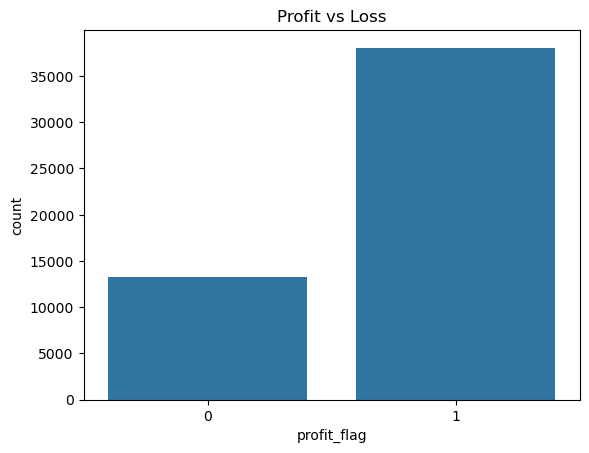

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt
# Binomial Plot
sns.countplot(x=df["profit_flag"])
plt.title("Profit vs Loss")
plt.show()

In [36]:
#POISSON DISTRIBUTION
# Create orders_per_day 
orders_per_day = df.groupby(df["Order Date"].dt.date).size()

# Group orders per day

df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)
orders_per_day.head()



# The ‘Order Date’ column was converted to datetime format using day-first parsing. 
# Orders were grouped by date to obtain daily counts, which are suitable for Poisson distribution analysis.

Order Date
2011-01-01     6
2011-01-02     1
2011-01-03    20
2011-01-04    16
2011-01-05     7
dtype: int64

In [37]:
#Calculate lambda (λ)

lam = orders_per_day.mean()
print(lam)

#The average number of orders per day (λ) is approximately 35.87, which represents the rate parameter for the Poisson distribution.

35.86713286713287


In [38]:
# Poisson PMF
from scipy.stats import poisson
poisson.pmf(5, mu=lam)

# The probability of observing exactly 5 orders in a day is extremely low (approximately 1.31 × 10⁻¹⁰), 
# indicating that such an event is highly unlikely given the average rate of orders.

np.float64(1.3104008800068606e-10)

In [39]:
# Poisson CDF
poisson.cdf(5, mu=lam)

# The cumulative probability of observing 5 or fewer orders in a day is extremely low (approximately 1.51 × 10⁻¹⁰),
# indicating that such events are highly unlikely given the average rate of orders

np.float64(1.5152491943227473e-10)

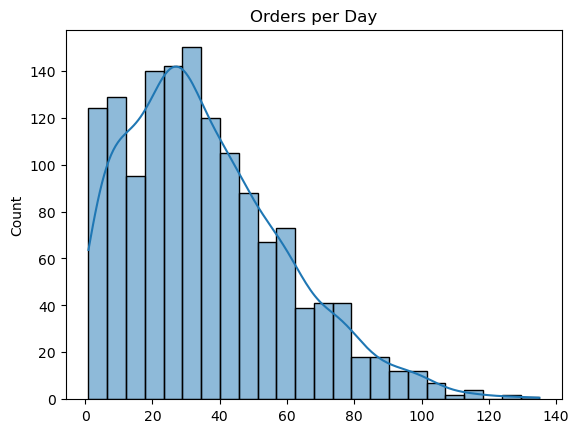

In [40]:
#Poisson Plot
sns.histplot(orders_per_day, kde=True)
plt.title("Orders per Day")
plt.show()

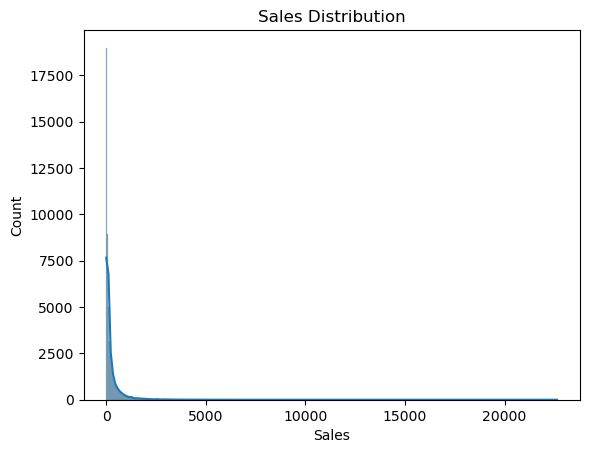

In [41]:
# Histogram + KDE
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(df["Sales"], kde=True)
plt.title("Sales Distribution")
plt.show()

# No the data is right-skewed and not perfectly normal.
# it is skewed due to presence of extreme high sales values.
# KDE shows a smooth estimate of the probability density function.

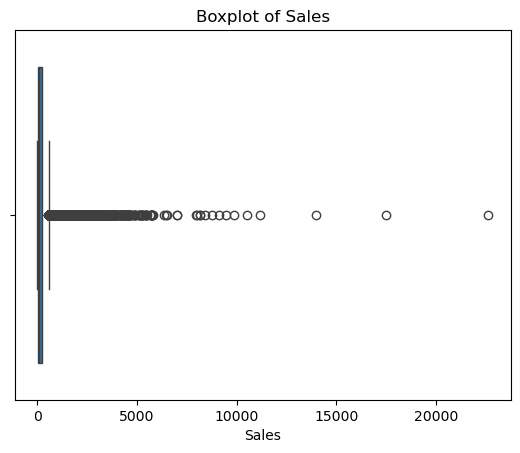

In [42]:
sns.boxplot(x=df["Sales"])
plt.title("Boxplot of Sales")
plt.show()
#The boxplot shows a large number of outliers on the higher side of sales, 
#indicating a highly skewed distribution with extreme values significantly greater than the median.

In [43]:
# ANOVA 
# Prepare Groups (Region vs Sales)
region_groups = df.groupby("Region")["Sales"].apply(list)

In [44]:
# Perform ANOVA
from scipy.stats import f_oneway

f_stat, p_val = f_oneway(*region_groups)

print("F-statistic:", f_stat)
print("p-value:", p_val)

#Since the p-value is significantly less than 0.05,
#we reject the null hypothesis and conclude that there is a statistically significant difference in sales across different regions.
#Null Hypothesis (H₀):
#There is no significant difference in sales across regions.
#Alternative Hypothesis (H₁):
#There is a significant difference in sales across regions.

F-statistic: 55.48438366881456
p-value: 7.28547664877952e-134


In [45]:
#Interpretation
if p_val < 0.05:
    print("Reject Null Hypothesis (Significant difference between regions)")
else:
    print("Fail to Reject Null Hypothesis (No significant difference)")

Reject Null Hypothesis (Significant difference between regions)


In [46]:
#MANOVA
from statsmodels.multivariate.manova import MANOVA

manova = MANOVA.from_formula('Sales + Profit ~ Region', data=df)
print(manova.mv_test())

# Hypothesis
# H₀:No significant difference in Sales and Profit across regions
# H₁:Significant difference exists
#Since the p-value (Wilks’ Lambda) is less than 0.05, we reject the null hypothesis and 
#conclude that there is a statistically significant effect of region on the combined dependent variables (Sales and Profit)

                    Multivariate linear model
                                                                 
-----------------------------------------------------------------
        Intercept        Value  Num DF   Den DF   F Value  Pr > F
-----------------------------------------------------------------
           Wilks' lambda 0.9886 2.0000 51276.0000 295.5465 0.0000
          Pillai's trace 0.0114 2.0000 51276.0000 295.5465 0.0000
  Hotelling-Lawley trace 0.0115 2.0000 51276.0000 295.5465 0.0000
     Roy's greatest root 0.0115 2.0000 51276.0000 295.5465 0.0000
-----------------------------------------------------------------
                                                                 
-----------------------------------------------------------------
         Region         Value   Num DF    Den DF   F Value Pr > F
-----------------------------------------------------------------
          Wilks' lambda 0.9822 24.0000 102552.0000 38.5452 0.0000
         Pillai's trace 0.0179

In [47]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [48]:
#Step 2 - Prepare dataset
X = df[["Sales", "Quantity", "Discount"]]
y = df["profit_flag"]

In [49]:
#step 3- Train Test Split
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [50]:
#step 4- Train model
model = GaussianNB()
model.fit(x_train, y_train)

,priors,None
,var_smoothing,1e-09


In [51]:
#step5- Prediction
y_pred = model.predict(x_test)

In [52]:
#step6- Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9158705400662898


In [53]:
#step 7- Confusion Matrix(numeric)
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix\n", cm)


Confusion Matrix
 [[2053  643]
 [ 220 7342]]


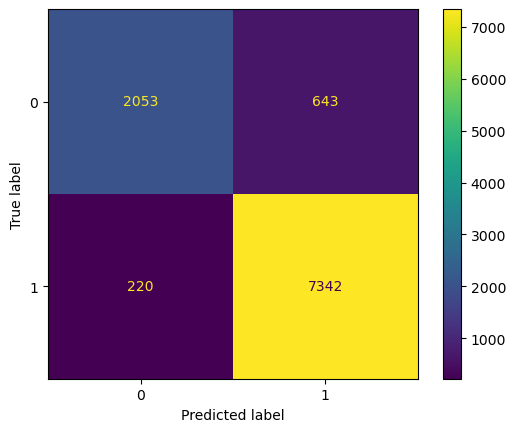

In [54]:
#step 8- Confusion Matrix(visual)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

In [55]:
#Train Model
# Linear Regression Model
model = LinearRegression()
model.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [56]:
# Predictions
y_pred = model.predict(x_test)
y_pred

array([0.32380925, 0.65171194, 0.97731553, ..., 0.97966001, 0.98122971,
       0.97731453], shape=(10258,))

In [57]:
# Evaluation Metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("R2 Score:", r2)

MSE: 0.07214104445586794
R2 Score: 0.6276500890628455


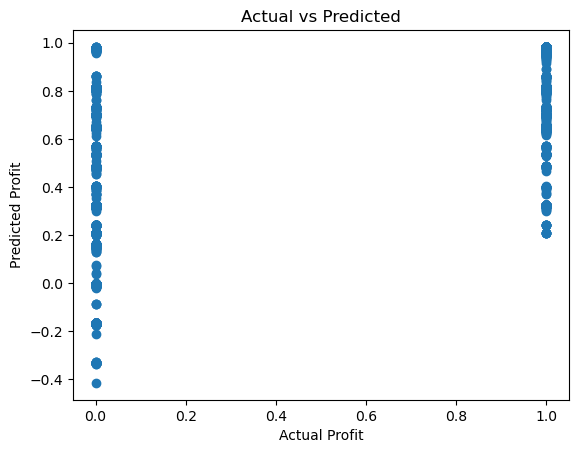

In [58]:
#Actual vs Predicted Plot

plt.scatter(y_test, y_pred)
plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")
plt.title("Actual vs Predicted")
plt.show()

In [59]:
#OLS + ANOVA + interaction + Tukey + t-test + MANOVA
#OLS + ANOVA (single factor)
# OLS Model 1 (Sales vs Region)
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.multivariate.manova import MANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.stats import ttest_ind
import seaborn as sns

model1 = ols('Sales ~ Region', data=df).fit()

anova1 = sm.stats.anova_lm(model1, typ=1)
print(anova1)

               df        sum_sq       mean_sq          F         PR(>F)
Region       12.0  1.562847e+08  1.302373e+07  55.484384  7.285477e-134
Residual  51277.0  1.203614e+10  2.347278e+05        NaN            NaN


In [60]:
#OLS with multiple factors
# OLS Model 2 (Sales vs Category + Region)
model2 = ols('Sales ~ Category + Region', data=df).fit()

anova2 = sm.stats.anova_lm(model2, typ=1)
print(anova2)

               df        sum_sq       mean_sq            F         PR(>F)
Category      2.0  1.273276e+09  6.366381e+08  3020.847131   0.000000e+00
Region       12.0  1.130302e+08  9.419180e+06    44.694003  1.553615e-106
Residual  51275.0  1.080611e+10  2.107482e+05          NaN            NaN


In [61]:
#Interaction model
# OLS Model 3 (with interaction)
model3 = ols('Sales ~ Category * Region', data=df).fit()

anova3 = sm.stats.anova_lm(model3, typ=1)
print(anova3)

                      df        sum_sq       mean_sq            F  \
Category             2.0  1.273276e+09  6.366381e+08  3039.642897   
Region              12.0  1.130302e+08  9.419180e+06    44.972090   
Category:Region     24.0  7.184676e+07  2.993615e+06    14.293083   
Residual         51251.0  1.073427e+10  2.094450e+05          NaN   

                        PR(>F)  
Category          0.000000e+00  
Region           3.074616e-107  
Category:Region   5.412129e-58  
Residual                   NaN  


In [62]:
#POST-HOC TEST (Tukey)
# Tukey Test
tukey = pairwise_tukeyhsd(endog=df['Sales'], groups=df['Region'], alpha=0.05)
print(tukey)

           Multiple Comparison of Means - Tukey HSD, FWER=0.05           
    group1         group2      meandiff p-adj    lower     upper   reject
-------------------------------------------------------------------------
        Africa         Canada    3.4237    1.0  -81.8435   88.6909  False
        Africa      Caribbean   21.0138  0.951  -24.6591   66.6867  False
        Africa        Central   83.0043    0.0   54.8375  111.1711   True
        Africa   Central Asia  196.7227    0.0  154.0666  239.3788   True
        Africa           EMEA  -10.5659 0.9977  -43.3363   22.2046  False
        Africa           East   67.4677    0.0   29.1768  105.7587   True
        Africa          North   89.9813    0.0   56.8147  123.1479   True
        Africa     North Asia  191.9673    0.0  151.1811  232.7535   True
        Africa        Oceania   144.642    0.0  108.5805  180.7035   True
        Africa          South   70.0507    0.0   39.2396  100.8617   True
        Africa Southeast Asia  111.785

In [63]:
# T-test
group1 = df[df['Segment'] == 'Consumer']['Sales']
group2 = df[df['Segment'] == 'Corporate']['Sales']

t_stat, p_val = ttest_ind(group1, group2)

print("t-statistic:", t_stat)
print("p-value:", p_val)

t-statistic: -0.5085545063631788
p-value: 0.6110671988608818


In [64]:
# Z-test (approx using normal)
from statsmodels.stats.weightstats import ztest

z_stat, p_val = ztest(df["Sales"], value=250)
print("Z-stat:", z_stat)
print("p-value:", p_val)

#Since the p-value is greater than 0.05, we fail to reject the null hypothesis and conclude that 
#there is no significant difference between the sample mean of sales and the hypothesized value.

Z-stat: -1.6301167284969094
p-value: 0.10307682879875288


In [65]:
#ONE-SAMPLE T-TEST
from scipy.stats import ttest_1samp

t_stat, p_val = ttest_1samp(df["Sales"], popmean=250)

print("t-stat:", t_stat)
print("p-value:", p_val)

#p > 0.05 → Fail to reject H₀
#No significant difference between sample mean and 250.

t-stat: -1.630116728496909
p-value: 0.10308296939821564


In [66]:
#TWO-SAMPLE T-TEST
from scipy.stats import ttest_ind

g1 = df[df["Segment"]=="Consumer"]["Sales"]
g2 = df[df["Segment"]=="Corporate"]["Sales"]

t_stat, p_val = ttest_ind(g1, g2)
print(t_stat, p_val)

#p > 0.05 → Fail to reject H₀
#No significant difference between Consumer and Corporate sales.

-0.5085545063631788 0.6110671988608818


In [67]:
#CHI-SQUARE (INDEPENDENCE)
from scipy.stats import chi2_contingency

table = pd.crosstab(df["Segment"], df["Region"])

chi2, p, dof, exp = chi2_contingency(table)

print("Chi2:", chi2)
print("p-value:", p)

#p < 0.05 → Reject H₀
#Segment and Region are dependent (significant association exists).

Chi2: 38.99310388434618
p-value: 0.027354738562463815


In [68]:
#CHI-SQUARE (GOODNESS OF FIT)
from scipy.stats import chisquare

obs = df["Region"].value_counts()
chisquare(obs)

#The observed distribution significantly differs from the expected distribution.

Power_divergenceResult(statistic=np.float64(22202.34720218366), pvalue=np.float64(0.0))

In [69]:
#SIGN TEST
from statsmodels.stats.descriptivestats import sign_test

sign_test(df["Sales"] - df["Sales"].median())

#Since the p-value is greater than 0.05, we fail to reject the null hypothesis and 
#conclude that there is no significant difference between the sample median and the hypothesized median.

(np.float64(0.0), 1.0)

In [70]:
#RANK SUM TEST (MANN-WHITNEY)
from scipy.stats import mannwhitneyu

mannwhitneyu(g1, g2)

#p > 0.05 → Fail to reject H₀
#No significant difference between the two groups.

MannwhitneyuResult(statistic=np.float64(203717376.0), pvalue=np.float64(0.4742745663107294))

In [71]:
#KRUSKAL-WALLIS TEST
from scipy.stats import kruskal

groups = [group["Sales"].values for name, group in df.groupby("Region")]

kruskal(*groups)

#p < 0.05 → Reject H₀
#Significant difference exists between regions.

KruskalResult(statistic=np.float64(1976.9031203845052), pvalue=np.float64(0.0))

In [72]:
# MANN-WHITNEY (CORRECTED)
#Compare Furniture vs Technology (Category)
from scipy.stats import mannwhitneyu

# H0: Sales distributions are equal

g1 = df_clean[df_clean['Category'] == 'Furniture']['Sales'].dropna()
g2 = df_clean[df_clean['Category'] == 'Technology']['Sales'].dropna()

u_stat, p_val = mannwhitneyu(g1, g2, alternative='two-sided')

print(f"Mann-Whitney U Statistic : {u_stat:.4f}")
print(f"p-value                 : {p_val:.6f}")

if p_val < 0.05:
    print("Decision: Reject H0 – Distributions are significantly different")
else:
    print("Decision: Fail to Reject H0 – No significant difference")

Mann-Whitney U Statistic : 37060640.0000
p-value                 : 0.000000
Decision: Reject H0 – Distributions are significantly different


In [73]:
#WILCOXON SIGNED-RANK (PAIRED)
#Compare Sales vs Profit (paired)

from scipy.stats import wilcoxon

# Paired test: Sales vs Profit

df_paired = df_clean[['Sales','Profit']].dropna()

w_stat, p_val_paired = wilcoxon(df_paired['Sales'], df_paired['Profit'])

print(f"Wilcoxon Signed-Rank Statistic : {w_stat:.4f}")
print(f"p-value                       : {p_val_paired:.6f}")

if p_val_paired < 0.05:
    print("Decision: Reject H0 – Sales and Profit are significantly different")
else:
    print("Decision: Fail to Reject H0")

Wilcoxon Signed-Rank Statistic : 0.0000
p-value                       : 0.000000
Decision: Reject H0 – Sales and Profit are significantly different


In [74]:
#Friedman Test (FINAL CORRECT VERSION)
#Compare Discount across 3 Categories
from scipy.stats import friedmanchisquare

np.random.seed(42)

# Take 3 categories
g = list(df_clean.groupby('Category'))[:3]

# Ensure equal sample size
n = min(len(g[0][1]), len(g[1][1]), len(g[2][1]), 100)

g1 = g[0][1]['Discount'].dropna().sample(n).values
g2 = g[1][1]['Discount'].dropna().sample(n).values
g3 = g[2][1]['Discount'].dropna().sample(n).values

fried_stat, fried_p = friedmanchisquare(g1, g2, g3)

print(f"Friedman Test Statistic : {fried_stat:.4f}")
print(f"p-value                : {fried_p:.6f}")

if fried_p < 0.05:
    print("Decision: Reject H0 – Discount differs across categories")
else:
    print("Decision: Fail to Reject H0 – No significant difference")

Friedman Test Statistic : 4.8383
p-value                : 0.088998
Decision: Fail to Reject H0 – No significant difference


In [75]:
from scipy.stats import friedmanchisquare

g = list(df.groupby("Region"))[:3]

# take equal size (minimum length)
min_len = min(len(g[0][1]), len(g[1][1]), len(g[2][1]))

x1 = g[0][1]["Sales"].values[:min_len]
x2 = g[1][1]["Sales"].values[:min_len]
x3 = g[2][1]["Sales"].values[:min_len]

friedmanchisquare(x1, x2, x3)

#pSince the p-value is less than 0.05, we reject the null hypothesis and 
#conclude that there is a statistically significant difference between the related groups.”

FriedmanchisquareResult(statistic=np.float64(608.765625), pvalue=np.float64(6.430195024591173e-133))

In [76]:
# Types of matrices
A = np.array([[1,2],[3,4]])

print("Matrix:\n", A)
print("Transpose:\n", A.T)
print("Inverse:\n", np.linalg.inv(A))
print("Determinant:", np.linalg.det(A))
print("Eigenvalues:", np.linalg.eigvals(A))

#Matrix operations including transpose, inverse, determinant, and eigenvalues were computed. 
#Since the determinant is non-zero, the matrix is invertible.

Matrix:
 [[1 2]
 [3 4]]
Transpose:
 [[1 3]
 [2 4]]
Inverse:
 [[-2.   1. ]
 [ 1.5 -0.5]]
Determinant: -2.0000000000000004
Eigenvalues: [-0.37228132  5.37228132]


In [77]:
#BAYESIAN INFERENCE (GLOBAL SUPERSTORE)
# Bayesian Update on Sales

# Bayesian update: Prior belief on mean Sales, update with observed data
# Prior: mu ~ N(prior_mean, prior_std^2)
# Likelihood: data ~ N(mu, sigma^2) with known sigma
# Posterior: also Normal (conjugate prior)

data = df_clean['Sales'].dropna().values

prior_mean = 300   # assumed prior mean of Sales
prior_std = 100    # uncertainty in prior

sigma_known = np.std(data)   # from MLE
n_obs = len(data)
xbar_obs = np.mean(data)

In [78]:
# Posterior parameters (conjugate Gaussian)

posterior_var = 1 / (1/prior_std**2 + n_obs/sigma_known**2)
posterior_mean = posterior_var * (prior_mean/prior_std**2 + n_obs*xbar_obs/sigma_known**2)
posterior_std = np.sqrt(posterior_var)

print(f"Prior Mean        : {prior_mean}")
print(f"Observed Mean     : {xbar_obs:.4f}")
print(f"Posterior Mean    : {posterior_mean:.4f}")
print(f"Posterior Std     : {posterior_std:.6f}")

Prior Mean        : 300
Observed Mean     : 162.1372
Posterior Mean    : 162.1489
Posterior Std     : 0.921001


In [79]:
# Posterior Credible Interval
from scipy.stats import norm

posterior_dist = norm(loc=posterior_mean, scale=posterior_std)

lower_95 = posterior_dist.ppf(0.025)
upper_95 = posterior_dist.ppf(0.975)

print(f"95% Posterior Credible Interval: ({lower_95:.4f}, {upper_95:.4f})")

95% Posterior Credible Interval: (160.3438, 163.9540)


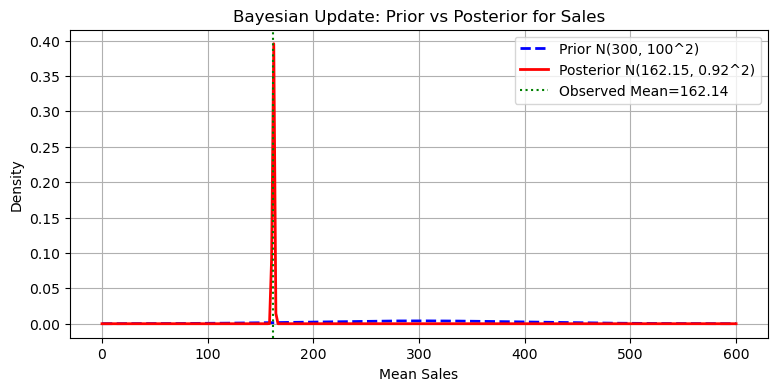

In [80]:
# Plot Prior vs Posterior

mu_range = np.linspace(prior_mean - 3*prior_std, prior_mean + 3*prior_std, 300)

prior_pdf = norm.pdf(mu_range, prior_mean, prior_std)
posterior_pdf = norm.pdf(mu_range, posterior_mean, posterior_std)

plt.figure(figsize=(9,4))
plt.plot(mu_range, prior_pdf, 'b--', label=f'Prior N({prior_mean}, {prior_std}^2)', lw=2)
plt.plot(mu_range, posterior_pdf, 'r-', label=f'Posterior N({posterior_mean:.2f}, {posterior_std:.2f}^2)', lw=2)

plt.axvline(xbar_obs, color='green', linestyle=':', label=f'Observed Mean={xbar_obs:.2f}')

plt.title('Bayesian Update: Prior vs Posterior for Sales')
plt.xlabel('Mean Sales')
plt.ylabel('Density')
plt.legend()
plt.grid(True)
plt.show()

In [81]:
# Correlation & Covariance
import statsmodels.formula.api as smf
from statsmodels.tools.tools import add_constant

numeric_cols = ['Sales','Profit','Quantity','Discount']
df_num = df_clean[numeric_cols].dropna()

print("Correlation Matrix:")
print(df_num.corr().round(4))

Correlation Matrix:
           Sales  Profit  Quantity  Discount
Sales     1.0000  0.2538    0.2766   -0.1062
Profit    0.2538  1.0000    0.0445   -0.4716
Quantity  0.2766  0.0445    1.0000   -0.0092
Discount -0.1062 -0.4716   -0.0092    1.0000


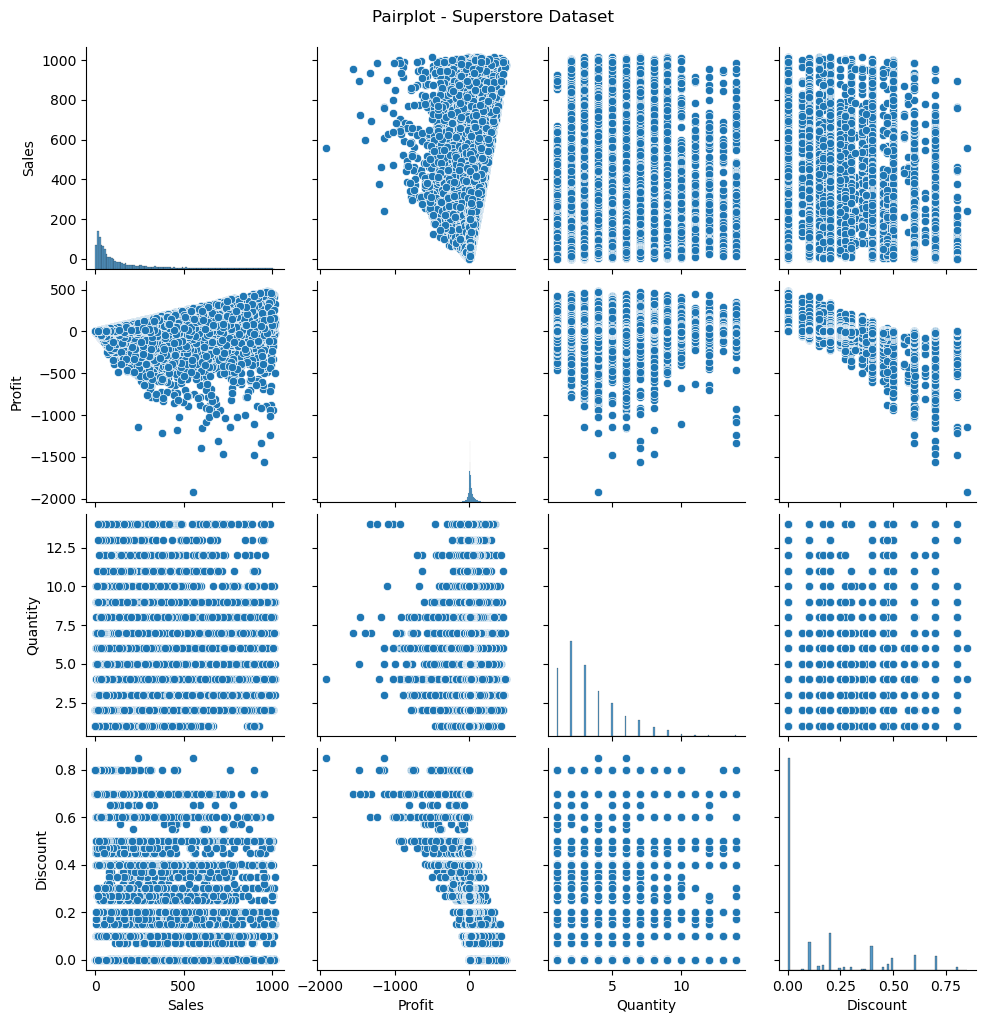

In [82]:
# Pairplot
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(df_num)
plt.suptitle("Pairplot - Superstore Dataset", y=1.02)
plt.show()

In [83]:
# Covariance matrix
print("Covariance Matrix:")
print(df_num.cov().round(2))

Covariance Matrix:
             Sales   Profit  Quantity  Discount
Sales     41335.03  4500.97    123.66     -4.64
Profit     4500.97  7610.33      8.53     -8.84
Quantity    123.66     8.53      4.83     -0.00
Discount     -4.64    -8.84     -0.00      0.05


In [84]:
#Simple Linear Regression
#Sales ~ Profit

import sklearn.linear_model as lm

X = df_num['Profit'].values.reshape(-1,1)
Y = df_num['Sales']

lr = lm.LinearRegression()
lr.fit(X, Y)

print(f"Intercept : {lr.intercept_:.4f}")
print(f"Coefficient (Profit): {lr.coef_[0]:.4f}")

Intercept : 153.3836
Coefficient (Profit): 0.5914


In [85]:
# RSS
RSS = np.sum((lr.intercept_ + lr.coef_*X - Y.values.reshape(-1,1))**2)
print(f"RSS : {RSS:.2f}")

RSS : 1884304092.75


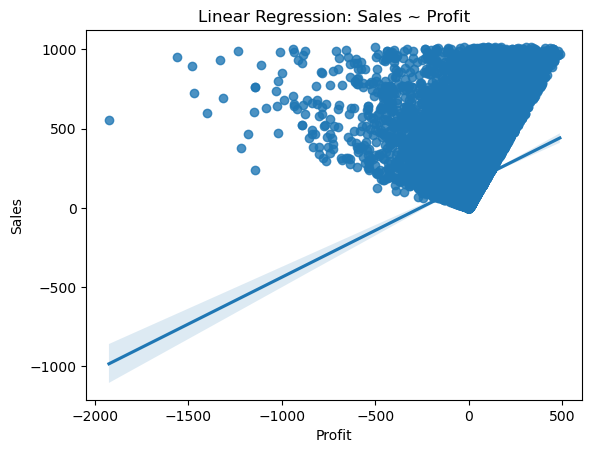

In [86]:
# Regression plot
sns.regplot(data=df_num, x='Profit', y='Sales', order=1)
plt.title("Linear Regression: Sales ~ Profit")
plt.show()

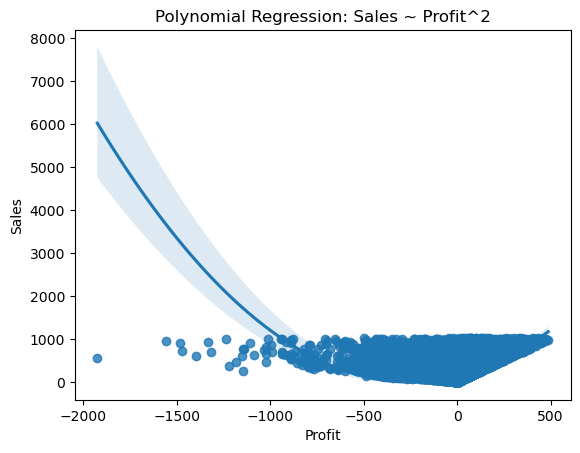

In [87]:
# Polynomial (order=2)
sns.regplot(data=df_num, x='Profit', y='Sales', order=2)
plt.title("Polynomial Regression: Sales ~ Profit^2")
plt.show()

In [88]:
# OLS summary
lm_fit = smf.ols('Sales ~ Profit', df_num).fit()
lm_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.064
Model:                            OLS   Adj. R-squared:                  0.064
Method:                 Least Squares   F-statistic:                     3354.
Date:                Thu, 16 Apr 2026   Prob (F-statistic):               0.00
Time:                        17:46:21   Log-Likelihood:            -3.2648e+05
No. Observations:               48725   AIC:                         6.530e+05
Df Residuals:                   48723   BIC:                         6.530e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    153.3836      0.904    169.740      0.000     151.612     155.155
Profit         0.5914      0.010     57.912      0.000       0.571       0.611
==============================================================================
Omnibus:                    21677.415   Durbin-Watson:                   0.643
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           100471.631
Skew:                           2.196   Prob(JB):                         0.00
Kurtosis:                       8.495   Cond. No.                         89.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [89]:
# Prediction
lm_fit.predict(pd.DataFrame({'Profit':[100, 500, 1000]}))

0    212.526557
1    449.098347
2    744.813084
dtype: float64

In [90]:
#Non-linear Transformation
df_num2 = df_num.copy()
df_num2['Profit2'] = df_num2['Profit']**2

lm_fit2 = smf.ols('Sales ~ Profit + Profit2', df_num2).fit()
3#lm_fit2.summary()

3

In [91]:
# Multiple Regression
lm_multi = smf.ols('Sales ~ Profit + Quantity + Discount', data=df_num).fit()
lm_multi.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.135
Model:                            OLS   Adj. R-squared:                  0.135
Method:                 Least Squares   F-statistic:                     2536.
Date:                Thu, 16 Apr 2026   Prob (F-statistic):               0.00
Time:                        17:46:27   Log-Likelihood:            -3.2456e+05
No. Observations:               48725   AIC:                         6.491e+05
Df Residuals:                   48721   BIC:                         6.492e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     69.3753      1.722     40.296      0.000      66.001      72.750
Profit         0.5785      0.011     51.897      0.000       0.557       0.600
Quantity      24.5677      0.390     62.994      0.000      23.803      25.332
Discount      12.5603      4.519      2.779      0.005       3.703      21.418
==============================================================================
Omnibus:                    20620.715   Durbin-Watson:                   0.757
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            90631.336
Skew:                           2.093   Prob(JB):                         0.00
Kurtosis:                       8.208   Cond. No.                         473.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [92]:
# Dummy Variable Regression (Category)
df_cat = df_clean[['Sales','Profit','Quantity','Discount','Category']].dropna().copy()

df_dummies = pd.get_dummies(df_cat, columns=['Category'], drop_first=True)

print(df_dummies.head())

        Sales    Profit  Quantity  Discount  Category_Office Supplies  \
196  1007.424   134.304         2       0.1                      True   
200   957.600     0.000         4       0.0                     False   
267   897.480   322.920         9       0.0                     False   
275   983.880   -11.160         8       0.1                     False   
289   934.248 -1331.652        14       0.6                     False   

     Category_Technology  
196                False  
200                 True  
267                False  
275                 True  
289                 True  


In [93]:
# Regression with category
lm_qual = smf.ols('Sales ~ Profit + Quantity + Discount + C(Category)', data=df_cat).fit()
lm_qual.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,184.2993,2.192,84.084,0.000,180.003,188.595
C(Category)[T.Office Supplies],-185.4643,1.985,-93.451,0.000,-189.354,-181.574
C(Category)[T.Technology],15.8705,2.462,6.445,0.000,11.044,20.697
Profit,0.4739,0.010,48.580,0.000,0.455,0.493
Quantity,26.4476,0.340,77.787,0.000,25.781,27.114
Discount,-25.8023,3.948,-6.536,0.000,-33.540,-18.065


In [94]:
# Interaction Terms
lm_interact = smf.ols('Sales ~ Profit * Discount', data=df_num).fit()
lm_interact.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,103.1510,1.054,97.868,0.000,101.085,105.217
Profit,2.0876,0.014,145.661,0.000,2.060,2.116
Discount,-7.8262,3.966,-1.974,0.048,-15.599,-0.054
Profit:Discount,-4.3706,0.031,-140.786,0.000,-4.431,-4.310


In [95]:
# VIF (Multicollinearity)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = add_constant(df_num[['Profit','Quantity','Discount']])

vif_df = pd.DataFrame()
vif_df['feature'] = X_vif.columns
vif_df['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

print(vif_df)

    feature       VIF
0     const  4.039419
1    Profit  1.288638
2  Quantity  1.002160
3  Discount  1.286199


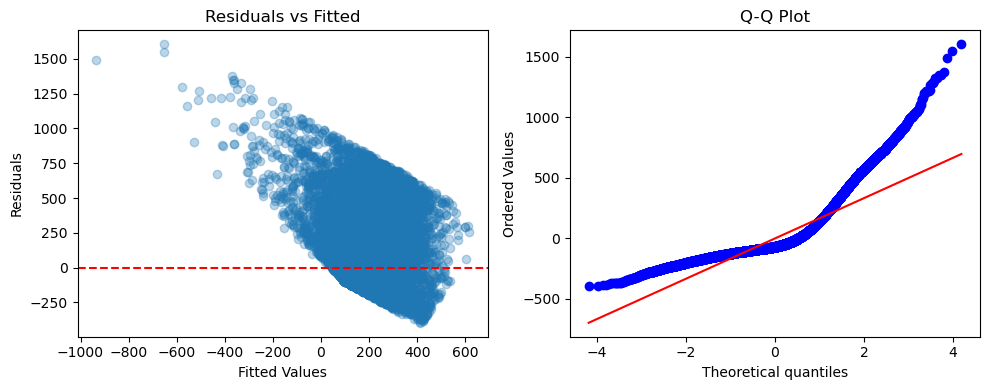

In [96]:
# Residual Diagnostics
import scipy.stats as stats

fitted = lm_multi.fittedvalues
residuals = lm_multi.resid

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.scatter(fitted, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted")

plt.subplot(1,2,2)
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot")

plt.tight_layout()
plt.show()


In [97]:
from sklearn.linear_model import Ridge, Lasso, LassoCV, RidgeCV, LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler

# Prepare dataset with Category
dfs = df_clean[['Sales','Profit','Quantity','Discount','Category']].dropna().copy()

# Dummy encoding
dfs = pd.get_dummies(dfs, columns=['Category'], drop_first=True)

# Features & Target
feature_cols = [c for c in dfs.columns if c != 'Sales']
X5 = dfs[feature_cols]
Y5 = dfs['Sales']

# Train-Test Split
x_train, x_test, y_train, y_test = train_test_split(X5, Y5, test_size=0.2, random_state=42)

# Scaling
scaler = StandardScaler()
x_train_sc = scaler.fit_transform(x_train)
x_test_sc = scaler.transform(x_test)

print("Features:", feature_cols)
print("Train size:", x_train.shape, "| Test size:", x_test.shape)

Features: ['Profit', 'Quantity', 'Discount', 'Category_Office Supplies', 'Category_Technology']
Train size: (38980, 5) | Test size: (9745, 5)


In [98]:
#Ridge Regression
# Ridge with alpha=100
fitR = Ridge(alpha=100)
fitR.fit(x_train_sc, y_train)

print("Ridge Coefficients:", fitR.coef_)

y_pred_r = fitR.predict(x_test_sc)

print(f"Ridge R2  : {r2_score(y_test, y_pred_r):.4f}")
print(f"Ridge MSE : {mean_squared_error(y_test, y_pred_r):.2f}")

Ridge Coefficients: [ 41.24229242  57.43733112  -5.26725057 -87.98050226   7.2182432 ]
Ridge R2  : 0.3596
Ridge MSE : 26999.91


In [99]:
#RidgeCV (Optimal Alpha)
ridgecv = RidgeCV(alphas=np.logspace(-2, 3, 100), cv=5)
ridgecv.fit(x_train_sc, y_train)

y_pred_rcv = ridgecv.predict(x_test_sc)

print("Optimal Ridge alpha:", ridgecv.alpha_)
print(f"R2   : {r2_score(y_test, y_pred_rcv):.4f}")
print(f"MAE  : {mean_absolute_error(y_test, y_pred_rcv):.2f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, y_pred_rcv)):.2f}")

Optimal Ridge alpha: 30.538555088334157
R2   : 0.3596
MAE  : 105.07
RMSE : 164.31


In [100]:
#Lasso Regression
# Lasso with alpha=1
fitL = Lasso(alpha=1)
fitL.fit(x_train_sc, y_train)

print("Lasso Coefficients:", fitL.coef_)

y_pred_l = fitL.predict(x_test_sc)

print(f"Lasso R2  : {r2_score(y_test, y_pred_l):.4f}")
print(f"Lasso MSE : {mean_squared_error(y_test, y_pred_l):.2f}")

Lasso Coefficients: [ 40.85000248  56.5617344   -4.46249036 -87.62316871   6.46526046]
Lasso R2  : 0.3593
Lasso MSE : 27012.08


In [101]:
# LassoCV (Best Alpha)
lassocv = LassoCV(alphas=None, cv=5, max_iter=10000)
lassocv.fit(x_train_sc, y_train)

y_pred_lcv = lassocv.predict(x_test_sc)

print("Optimal Lasso alpha:", lassocv.alpha_)
print(f"R2   : {r2_score(y_test, y_pred_lcv):.4f}")
print(f"MAE  : {mean_absolute_error(y_test, y_pred_lcv):.2f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, y_pred_lcv)):.2f}")

C:\Users\kanik\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1641: FutureWarning: 'alphas=None' is deprecated and will be removed in 1.9, at which point the default value will be set to 100. Set 'alphas=100' to silence this warning.
  warnings.warn(


Optimal Lasso alpha: 0.09201529925392675
R2   : 0.3596
MAE  : 105.07
RMSE : 164.31


In [102]:
# Cross Validation 
# Cross-validation score
cv_scores = cross_val_score(Ridge(alpha=ridgecv.alpha_), X5, Y5, cv=5, scoring='r2')

print("Cross-validation R2 scores:", cv_scores)
print("Mean CV R2:", np.mean(cv_scores))

Cross-validation R2 scores: [-1.56809207 -0.17538396 -2.57299882 -5.73320107 -6.3373322 ]
Mean CV R2: -3.27740162614567


In [103]:
# Lasso with alpha=100
fitL = Lasso(alpha=100)
fitL.fit(x_train_sc, y_train)

print("Lasso Coefficients:", fitL.coef_)

Lasso Coefficients: [ 0.  0. -0. -0.  0.]


In [104]:
# LassoCV (Optimal Alpha)
lassocv = LassoCV(alphas=np.logspace(-2, 3, 50), cv=5, max_iter=10000)
lassocv.fit(x_train_sc, y_train)

y_pred_lcv = lassocv.predict(x_test_sc)

print(f"Optimal Lasso alpha : {lassocv.alpha_:.6f}")
print(f"R2   : {r2_score(y_test, y_pred_lcv):.4f}")
print(f"MAE  : {mean_absolute_error(y_test, y_pred_lcv):.2f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, y_pred_lcv)):.2f}")

Optimal Lasso alpha : 0.015999
R2   : 0.3596
MAE  : 105.06
RMSE : 164.31


In [105]:
# Feature Selection by Lasso
total_features = X5.shape[1]
active_features = np.sum(lassocv.coef_ != 0)
removed_features = total_features - active_features

print(f"Total Features   : {total_features}")
print(f"Features Retained: {active_features}")
print(f"Features Dropped : {removed_features}")

Total Features   : 5
Features Retained: 5
Features Dropped : 0


In [106]:
#Top Features
coefs = pd.Series(lassocv.coef_, index=X5.columns)

print("\nAll Feature Coefficients (Lasso):")
print(coefs.abs().sort_values(ascending=False))


All Feature Coefficients (Lasso):
Category_Office Supplies    88.325521
Quantity                    57.570712
Profit                      41.344590
Category_Technology          7.001751
Discount                     5.232908
dtype: float64


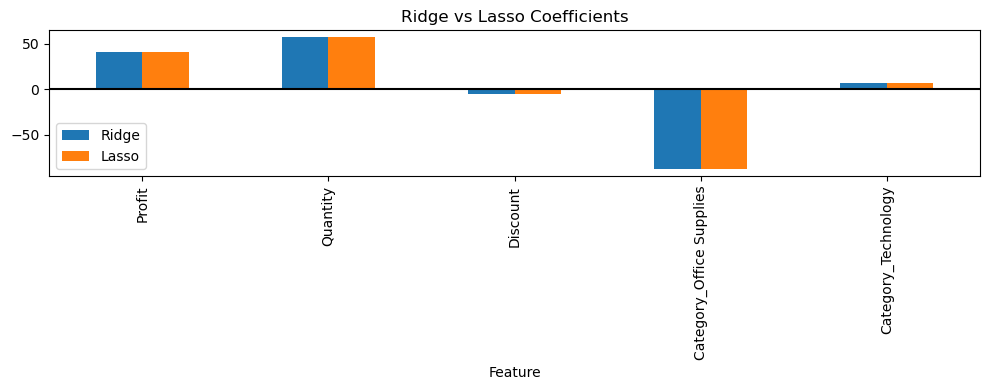

In [107]:
# Ridge vs Lasso Comparison
coef_compare = pd.DataFrame({
    'Feature': X5.columns,
    'Ridge': ridgecv.coef_,
    'Lasso': lassocv.coef_
})

coef_compare.set_index('Feature').plot(kind='bar', figsize=(10,4))
plt.title("Ridge vs Lasso Coefficients")
plt.axhline(0, color='black')
plt.tight_layout()
plt.show()

In [108]:
# CROSS VALIDATION (K-FOLD)
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

model_lin = LinearRegression()

K = 10
kfold = KFold(n_splits=K, shuffle=True, random_state=1)

mse_cv = cross_val_score(model_lin, X5, Y5, cv=kfold, scoring='neg_mean_squared_error')

print("10-Fold CV MSE per fold:")
print(mse_cv.round(2))

print(f"Mean CV MSE : {-mse_cv.mean():.2f}")
print(f"CV RMSE     : {np.sqrt(-mse_cv.mean()):.2f}")

10-Fold CV MSE per fold:
[-27801.79 -26211.21 -26777.98 -27407.66 -27607.92 -28061.83 -29888.56
 -25608.74 -25548.22 -26451.28]
Mean CV MSE : 27136.52
CV RMSE     : 164.73


In [109]:
#LOGISTIC REGRESSION (GLOBAL SUPERSTORE)
#Create Binary Target
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import statsmodels.api as sm

df6 = df_clean[['Sales','Profit','Quantity','Discount']].dropna().copy()

# Binary outcome: Profit > 0
df6['profit_flag'] = (df6['Profit'] > 0).astype(int)

print("Class Distribution:")
print(df6['profit_flag'].value_counts())

Class Distribution:
profit_flag
1    35965
0    12760
Name: count, dtype: int64


In [110]:
# Simple Logistic (statsmodels)
lm_logit = sm.Logit(df6['profit_flag'], sm.add_constant(df6['Discount'])).fit()

print(lm_logit.summary())

Optimization terminated successfully.
         Current function value: 0.225645
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:            profit_flag   No. Observations:                48725
Model:                          Logit   Df Residuals:                    48723
Method:                           MLE   Df Model:                            1
Date:                Thu, 16 Apr 2026   Pseudo R-squ.:                  0.6076
Time:                        17:47:03   Log-Likelihood:                -10995.
converged:                       True   LL-Null:                       -28017.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.5375      0.029    122.343      0.000       3.481       3.594
Discount     -13.3511      0.

In [111]:
# Odds Ratios
print("Coefficients (log-odds):")
print(lm_logit.params)

print("\nOdds Ratios:")
print(np.exp(lm_logit.params))

Coefficients (log-odds):
const        3.537489
Discount   -13.351111
dtype: float64

Odds Ratios:
const       34.380497
Discount     0.000002
dtype: float64


In [112]:
# Multiple Logistic Regression (sklearn)
X = df6[['Sales','Quantity','Discount']]
y = df6['profit_flag']

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=1000)
model.fit(x_train, y_train)

y_pred = model.predict(x_test)

In [113]:
# Evaluation Metrics
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))

Accuracy : 0.9223191380194972
Precision: 0.922089825847846
Recall   : 0.9775124930594115
F1 Score : 0.9489926554814365


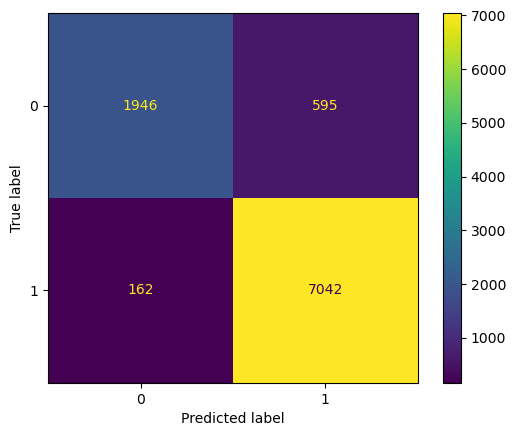

In [114]:
#Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

In [115]:
#Classification Report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.77      0.84      2541
           1       0.92      0.98      0.95      7204

    accuracy                           0.92      9745
   macro avg       0.92      0.87      0.89      9745
weighted avg       0.92      0.92      0.92      9745



In [116]:
#BINOMIAL MLE (GLOBAL SUPERSTORE – FINAL CODE)
#p 1 – Create Binary Variable
from scipy.stats import binom as scipy_binom

# Success = Profit > 0
df_clean['profit_flag'] = (df_clean['Profit'] > 0).astype(int)

n_binom = len(df_clean['profit_flag'])
k_binom = df_clean['profit_flag'].sum()

print(f"n = {n_binom}, k (profitable orders) = {k_binom}")

n = 48725, k (profitable orders) = 35965


C:\Users\kanik\AppData\Local\Temp\ipykernel_25780\885690852.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['profit_flag'] = (df_clean['Profit'] > 0).astype(int)


In [117]:
# Likelihood Function
p_range = np.linspace(0, 1, 200)

likelihood = scipy_binom.pmf(k_binom, n_binom, p_range)

In [118]:
#MLE
mle_p = p_range[np.argmax(likelihood)]

print(f"MLE p (analytical) : {k_binom/n_binom:.4f}")
print(f"MLE p (grid search): {mle_p:.4f}")

MLE p (analytical) : 0.7381
MLE p (grid search): 0.7387


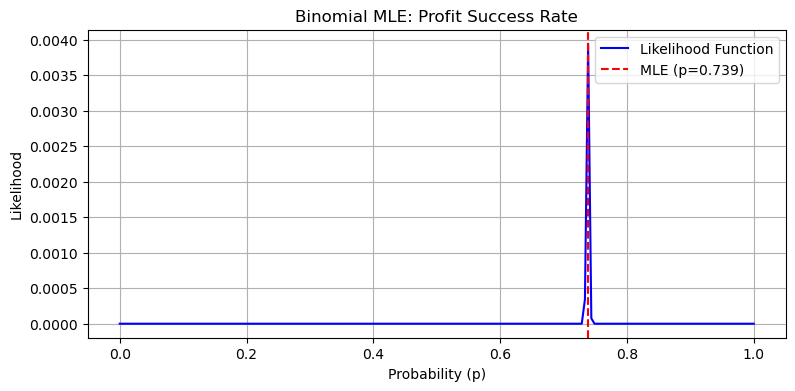

In [119]:
#Plot
plt.figure(figsize=(9,4))
plt.plot(p_range, likelihood, label='Likelihood Function', color='blue')
plt.axvline(mle_p, color='red', linestyle='--', label=f'MLE (p={mle_p:.3f})')

plt.title("Binomial MLE: Profit Success Rate")
plt.xlabel("Probability (p)")
plt.ylabel("Likelihood")
plt.legend()
plt.grid(True)
plt.show()

In [120]:
#Optimization (Advanced)
from scipy.optimize import minimize

def binomial_nll(p, n, k):
    if p <= 0 or p >= 1:
        return 1e10
    return -(k*np.log(p) + (n-k)*np.log(1-p))

result = minimize(binomial_nll, [0.5], args=(n_binom, k_binom), bounds=[(1e-5, 1-1e-5)])

print(f"Optimized MLE p : {result.x[0]:.4f}")
print(f"Analytical p    : {k_binom/n_binom:.4f}")

Optimized MLE p : 0.7381
Analytical p    : 0.7381
